Exécuter toutes les cellules dans l'ordre, depuis la racine du projet (le dossier `EnsembleA` doit être présent).

In [ ]:
# Chemin absolu sur robot : /home/equipeH/LOG635-Labo2/LOG635_Lab2.ipynb
# On ne sait pas le vrai chemin absolu du robot

from pathlib import Path
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import ImageGrid
import cv2
import numpy as np
import imutils
import random
import pickle

In [2]:
data_dir = Path.cwd() / "EnsembleA"
print(data_dir)
LABELS = ["Cercle2", "Cercle3", "Cercle4", "Cercle5", "Diamant2", "Diamant3", "Diamant4", "Diamant5", "Hexagone2", "Hexagone3", "Hexagone4", "Hexagone5", "Triangle2", "Triangle3", "Triangle4", "Triangle5"]

d:\ETS\LOG635\LOG635-Labo2\EnsembleA


# Partie 1: préparation de l'EnsembleB

On garde les symboles à 2 et à 5 motifs de chaque forme (classes 0, 3, 4, 7, 8, 11, 12, 15 de `LABELS`).

In [3]:
# On lit toutes les images de l'EnsembleA en grayscale
data_set = []

for first_level in data_dir.glob('*'):
    if first_level.is_dir() and not first_level.name.startswith('.'):
        for second_level in first_level.glob("*"):
            if second_level.is_dir() and not second_level.name.startswith('.'):
                label = Path(second_level).name
                if label in LABELS:
                    class_num = LABELS.index(label)
                    for file in second_level.glob("*.jpg"):
                        image = cv2.imread(str(file), cv2.IMREAD_GRAYSCALE)
                        data_set.append([image, class_num, label])

In [4]:
# EnsembleB: Cercle2, Cercle5, Diamant2, Diamant5, Hexagone2, Hexagone5, Triangle2, Triangle5
data_setB = []
for image in data_set:
    if image[1] in [0,3,4,7,8,11,12,15]:
        data_setB.append(image)

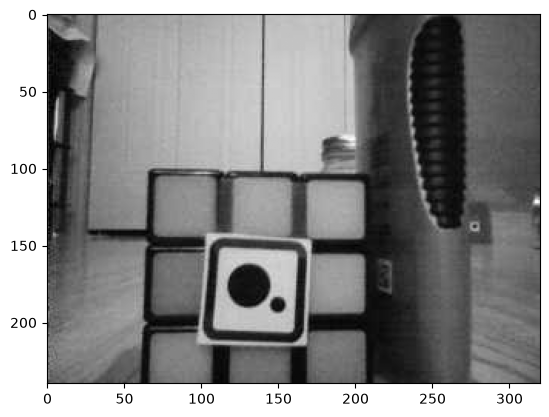

In [5]:
plt.imshow(data_setB[40][0], cmap="gray")

# Parties 2 et 3: prétraitement et extraction de la ROI

Les images sont lues en grayscale. On applique aucune augmentation de données. Le flou gaussien (3×3) sert uniquement à la détection des contours.

### Extraction de la ROI

Chaque image est seuillée, ensuite on cherche le cadre noir du marqueur parmi ses contours. Un contour est retenu s'il ressemble à un carré (20 à 110 px), loin du bord, et s'il entoure un intérieur clair qui contient une forme pleine. Cela permet de rejetter les grandes formes noires et les symboles des cubes.

Le meilleur candidat est redimensionné en 64×64. Son nombre de motifs et son écart-type sont conservés. Les images sans marqueur sont ignorées.

In [6]:
ROI_TAILLE = 64
COTE_MIN = 20
COTE_MAX = 110
RATIO_CARRE_MIN = 0.82
RATIO_CARRE_MAX = 1.22
SOMMETS_MIN = 4
SOMMETS_MAX = 8
RATIO_TROU_MIN = 0.35
RATIO_TROU_MAX = 0.82
ECART_TYPE_MIN = 18
AIRE_MOTIF_MIN = 8
CONTRASTE_MIN = 40
SOLIDITE_MIN = 0.8

HIERARCHIE_SUIVANT = 0
HIERARCHIE_PREMIER_ENFANT = 2
AUCUN_CONTOUR = -1


def touche_le_bord(image, x, y, w, h):
    hauteur_image, largeur_image = image.shape
    if x <= 1 or y <= 1:
        return True
    if x + w >= largeur_image - 1:
        return True
    if y + h >= hauteur_image - 1:
        return True
    return False


def a_une_taille_valide(w, h):
    largeur_valide = COTE_MIN <= w <= COTE_MAX
    hauteur_valide = COTE_MIN <= h <= COTE_MAX
    return largeur_valide and hauteur_valide


def est_presque_carre(w, h):
    ratio = w / h
    return RATIO_CARRE_MIN <= ratio <= RATIO_CARRE_MAX


def a_un_nombre_de_sommets_valide(contour):
    perimetre = cv2.arcLength(contour, True)
    sommets = cv2.approxPolyDP(contour, 0.04 * perimetre, True)
    return SOMMETS_MIN <= len(sommets) <= SOMMETS_MAX


def trou_a_une_taille_valide(contour_trou, w, h):
    x_trou, y_trou, largeur_trou, hauteur_trou = cv2.boundingRect(contour_trou)
    aire_trou = largeur_trou * hauteur_trou
    aire_cadre = w * h
    ratio = aire_trou / aire_cadre
    return RATIO_TROU_MIN <= ratio <= RATIO_TROU_MAX


def remplir_contour(image, contour):
    masque = np.zeros(image.shape, np.uint8)
    cv2.drawContours(masque, [contour], -1, 255, -1)
    return masque


def interieur_est_plus_clair(image, masque_trou, masque_anneau):
    pixels_interieur = image[masque_trou > 0]
    pixels_cadre = image[masque_anneau > 0]
    clarte_interieur = np.percentile(pixels_interieur, 90)
    clarte_cadre = np.median(pixels_cadre)
    contraste = clarte_interieur - clarte_cadre
    return contraste >= CONTRASTE_MIN


def calculer_solidite(image, masque_trou):
    noyau = np.ones((3, 3), np.uint8)
    masque_reduit = cv2.erode(masque_trou, noyau)
    est_interieur = masque_reduit > 0

    pixels_interieur = image[est_interieur]
    if pixels_interieur.size < 20:
        return 0

    pixels_en_colonne = pixels_interieur.reshape(-1, 1)
    seuil, _ = cv2.threshold(pixels_en_colonne, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    est_sombre = image < seuil
    zones_sombres = np.zeros(image.shape, np.uint8)
    zones_sombres[est_interieur & est_sombre] = 255

    formes, _ = cv2.findContours(zones_sombres, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if len(formes) == 0:
        return 0

    plus_grande_forme = max(formes, key=cv2.contourArea)
    enveloppe = cv2.convexHull(plus_grande_forme)
    aire_enveloppe = cv2.contourArea(enveloppe)
    if aire_enveloppe == 0:
        return 0

    aire_forme = cv2.contourArea(plus_grande_forme)
    return aire_forme / aire_enveloppe


def compter_motifs(contours, hierarchie, indice_trou):
    nombre_motifs = 0
    indice_motif = hierarchie[indice_trou][HIERARCHIE_PREMIER_ENFANT]

    while indice_motif != AUCUN_CONTOUR:
        aire_motif = cv2.contourArea(contours[indice_motif])
        if aire_motif > AIRE_MOTIF_MIN:
            nombre_motifs += 1
        indice_motif = hierarchie[indice_motif][HIERARCHIE_SUIVANT]

    return nombre_motifs


def evaluer_cadre(image, contours, hierarchie, indice_contour):
    contour = contours[indice_contour]
    x, y, w, h = cv2.boundingRect(contour)

    if touche_le_bord(image, x, y, w, h):
        return None
    if not a_une_taille_valide(w, h):
        return None
    if not est_presque_carre(w, h):
        return None
    if not a_un_nombre_de_sommets_valide(contour):
        return None

    indice_trou = hierarchie[indice_contour][HIERARCHIE_PREMIER_ENFANT]
    if indice_trou == AUCUN_CONTOUR:
        return None

    contour_trou = contours[indice_trou]
    if not trou_a_une_taille_valide(contour_trou, w, h):
        return None

    zone_cadre = image[y:y + h, x:x + w]
    ecart_type = np.std(zone_cadre)
    if ecart_type < ECART_TYPE_MIN:
        return None

    masque_cadre = remplir_contour(image, contour)
    masque_trou = remplir_contour(image, contour_trou)
    masque_anneau = cv2.subtract(masque_cadre, masque_trou)
    if not masque_anneau.any():
        return None
    if not interieur_est_plus_clair(image, masque_trou, masque_anneau):
        return None
    if calculer_solidite(image, masque_trou) < SOLIDITE_MIN:
        return None

    nombre_motifs = compter_motifs(contours, hierarchie, indice_trou)
    return {"x": x, "y": y, "w": w, "h": h, "nb_motifs": nombre_motifs, "ecart_type": ecart_type}


def score_candidat(candidat):
    return candidat["nb_motifs"] * 100 + candidat["ecart_type"]


def trouver_contours(image):
    image_floue = cv2.GaussianBlur(image, (3, 3), 0)
    image_seuillee = cv2.adaptiveThreshold(
        image_floue, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 31, 3
    )
    return cv2.findContours(image_seuillee, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)


def decouper_roi(image, candidat):
    haut = max(0, candidat["y"] - 1)
    gauche = max(0, candidat["x"] - 1)
    bas = candidat["y"] + candidat["h"] + 1
    droite = candidat["x"] + candidat["w"] + 1
    roi = image[haut:bas, gauche:droite]
    return cv2.resize(roi, (ROI_TAILLE, ROI_TAILLE))


def extraire_roi(image):
    contours, hierarchie = trouver_contours(image)
    if hierarchie is None:
        return None

    hierarchie = hierarchie[0]
    candidats = []
    for indice_contour in range(len(contours)):
        candidat = evaluer_cadre(image, contours, hierarchie, indice_contour)
        if candidat is not None:
            candidats.append(candidat)

    if len(candidats) == 0:
        return None

    meilleur = max(candidats, key=score_candidat)
    roi = decouper_roi(image, meilleur)
    return roi, meilleur["nb_motifs"], meilleur["ecart_type"]


data_setROI = []
for image, class_num, nom_classe in data_setB:
    resultat = extraire_roi(image)
    if resultat is None:
        continue

    roi, nb_motifs, ecart_type = resultat
    data_setROI.append([roi, nb_motifs, ecart_type, class_num])

print(f"{len(data_setROI)} images conservées sur {len(data_setB)}")

1566 images conservées sur 2371


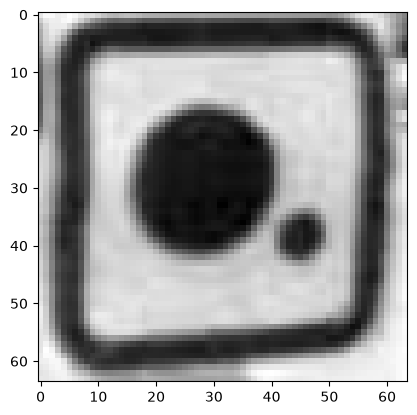

In [7]:
plt.imshow(data_setROI[10][0], cmap="gray")

# Partie 4:extraction des caractéristiques

Chaque image devient un vecteur de 4098 valeurs:

- Les 4096 pixels de la ROI 64×64, 
- le nombre de motifs détectés dans le cadre
- L'écart-type des niveaux de gris du cadre.

In [8]:
import numpy as np
import pickle

X1 = []
y1 = []

for item in data_setROI:
    image = item[0]
    nb_motifs = item[1] # nb motifs dans le cadre
    std_dev = item[2]   # écart-type (contraste) du cadre
    label = item[3]
    
    # On applatit l'image. Passe de 64x64 à 4096
    image_flattened = image.flatten()
    
    # Ajoute les caractéristiques à l'image aplatie. Ce qui fait (4096 + 2)
    features = np.append(image_flattened, [nb_motifs, std_dev])
    
    X1.append(features)
    y1.append(label)

# On convertit en array Numpy pour aider les calculs matriciels
X1 = np.array(X1)
y1 = np.array(y1)

# On sauvegarde dans les .pickle
with open("X1.pickle", "wb") as f:
    pickle.dump(X1, f)

with open("y1.pickle", "wb") as f:
    pickle.dump(y1, f)

print(f"Sauvegarde finie. Dimensions de X1: {X1.shape}")

Sauvegarde finie. Dimensions de X1: (1566, 4098)


In [9]:
# Les doublons sont exclus avec la même règle que la partie 6 (np.unique sur X1)
DOSSIER_ENSEMBLE_B = Path.cwd() / "EnsembleB"

_, indices_uniques = np.unique(X1, axis=0, return_index=True)
for indice in np.sort(indices_uniques):
    roi, nb_motifs, ecart_type, class_num = data_setROI[indice]
    nom_classe = LABELS[class_num]
    dossier = DOSSIER_ENSEMBLE_B / nom_classe
    dossier.mkdir(parents=True, exist_ok=True)
    cv2.imwrite(str(dossier / f"{indice:04d}_{nom_classe}.png"), roi)

print(f"{len(indices_uniques)} images enregistrées dans {DOSSIER_ENSEMBLE_B}")


1514 images enregistrées dans d:\ETS\LOG635\LOG635-Labo2\EnsembleB


# Partie 5 : Implémentation du réseau de neurones

Dimensions de X : (1566, 4098)
Dimensions de y : (1566,)
------------------------------
--- Échantillon 1 ---
Label: 0
Nb motifs détectés: 2.0
Écart-type (Contraste): 63.228762790673116


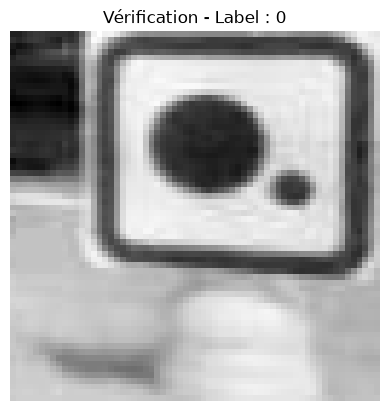

In [10]:
import numpy as np
import pickle
import matplotlib.pyplot as plt

with open("X1.pickle", "rb") as f:
    X = pickle.load(f)

with open("y1.pickle", "rb") as f:
    y = pickle.load(f)

print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)
print("-" * 30)

# On verifie l'intégrité la séparation des pixels et des features
# On test le premier élément pour s'assurer que les 4096 premières valeurs sont bien les pixels et les 2 dernières sont nos features
index_test = 1

# X contient 4098 valeurs : les 4096 premières sont les pixels, les 2 dernières sont nos features
pixels = X[index_test][:-2]
extra_features = X[index_test][-2:]
label = y[index_test]

# On transforme l'image en 64x64 pour s'assurer que l'ordre des pixels est bon
image_reconstruite = pixels.reshape((64, 64))

print(f"--- Échantillon {index_test} ---")
print(f"Label: {label}")
print(f"Nb motifs détectés: {extra_features[0]}")
print(f"Écart-type (Contraste): {extra_features[1]}")

plt.imshow(image_reconstruite, cmap="gray")
plt.title(f"Vérification - Label : {label}")
plt.axis("off")
plt.show()

### 5.1 : Préparation des données et initialisation du réseau
**Objectifs :**
1. **Normalisation & Standardisation** : Mettre les pixels à l'échelle [0, 1] et standardiser nos 2 caractéristiques (moyenne=0, variance=1) pour garantir la stabilité de l'apprentissage.
2. **Encodage One-Hot** : Convertir les étiquettes en vecteurs binaires (pour la prédiction de probabilités).
3. **Architecture** : Création de la classe `ReseauNeurones` et initialisation des matrices de poids ($W$) via la méthode de *He* (optimale pour éviter la disparition du gradient) et des biais ($b$) à zéro.

In [11]:
import numpy as np

# On sépare les pixels et les caractéristiques supplémentaires
X_pixels = X[:, :-2]
X_features = X[:, -2:]

# Normalisation des pixels (mise à l'échelle 0 à 1)
X_pixels_norm = X_pixels / 255.0

# On standardise les features (Z-score : moyenne 0, variance 1)
X_features_mean = np.mean(X_features, axis=0)
X_features_std = np.std(X_features, axis=0)
X_features_norm = (X_features - X_features_mean) / (X_features_std + 1e-8)

# On recombine de la matrice X
X_ready = np.hstack((X_pixels_norm, X_features_norm))

# On remap les étiquettes (ex: 0, 3, 15 -> 0, 1, ..., 7)
classes_uniques = np.unique(y)
num_classes = len(classes_uniques)
y_mapped = np.array([np.where(classes_uniques == val)[0][0] for val in y])

# One-Hot Encoding pour y
y_one_hot = np.zeros((y_mapped.size, num_classes))
y_one_hot[np.arange(y_mapped.size), y_mapped] = 1

print("Dimensions de X_ready:", X_ready.shape)
print("Dimensions de y_one_hot:", y_one_hot.shape)

class ReseauNeurones:
    def __init__(self, input_size, hidden_size, output_size):
        # Initialisation de He
        self.W1 = np.random.randn(input_size, hidden_size) * np.sqrt(2. / input_size)
        self.b1 = np.zeros((1, hidden_size))
        
        self.W2 = np.random.randn(hidden_size, output_size) * np.sqrt(2. / hidden_size)
        self.b2 = np.zeros((1, output_size))
        
        print(f"Réseau initialisé: {input_size} entrées -> {hidden_size} neurones cachés -> {output_size} sorties")

nn = ReseauNeurones(input_size=X_ready.shape[1], hidden_size=128, output_size=num_classes)

Dimensions de X_ready: (1566, 4098)
Dimensions de y_one_hot: (1566, 8)
Réseau initialisé: 4098 entrées -> 128 neurones cachés -> 8 sorties


### 5.2 : Propagation avant (Forward Pass) et fonctions d'activation
**Objectifs :**
1. **Fonctions d'activation :** Ajout des fonctions mathématiques `ReLU`, `Sigmoïde` et `Tanh` pour la couche cachée, avec un système simple pour passer de l'une à l'autre.
2. **Softmax :** Ajout de la fonction Softmax sur la couche de sortie pour transformer nos valeurs brutes (logits) en probabilités (somme = 1) pour nos 8 classes.
3. **Propagation avant (`forward`) :** Calcul matriciel ($Z = X \cdot W + b$) suivi de l'activation ($A = f(Z)$) de la couche d'entrée jusqu'à la sortie. Mise en cache des résultats `Z` et `A` pour la future rétropropagation.

In [12]:
import numpy as np

class ReseauNeurones:
    def __init__(self, input_size, hidden_size, output_size, activation_par_defaut='relu'):
        # Initialisation des poids (He) et biais
        self.W1 = np.random.randn(input_size, hidden_size) * np.sqrt(2. / input_size)
        self.b1 = np.zeros((1, hidden_size))
        
        self.W2 = np.random.randn(hidden_size, output_size) * np.sqrt(2. / hidden_size)
        self.b2 = np.zeros((1, output_size))
        
        self.activation_par_defaut = activation_par_defaut
        print(f"Réseau initialisé: {input_size} entrées -> {hidden_size} neurones ({self.activation_par_defaut}) -> {output_size} sorties")

    # Fonctions d'activation pour la couche cachée
    
    def relu(self, Z):
        return np.maximum(0, Z)

    def sigmoid(self, Z):
        # np.clip évite le dépassement de capacité (overflow) avec np.exp
        Z_clipped = np.clip(Z, -500, 500)
        return 1 / (1 + np.exp(-Z_clipped))

    def tanh(self, Z):
        return np.tanh(Z)

    # Fonction d'activation pour la couche de sortie (classification multiclasse)
    
    def softmax(self, Z):
        # Stabilité numérique : on soustrait le maximum de chaque ligne avant l'exponentielle
        exp_Z = np.exp(Z - np.max(Z, axis=1, keepdims=True))
        return exp_Z / np.sum(exp_Z, axis=1, keepdims=True)

    # Propagation Avant
    
    def forward(self, X, activation=None):
        if activation is None:
            activation = self.activation_par_defaut
            
        # La couche cachée
        self.Z1 = np.dot(X, self.W1) + self.b1
        
        if activation == 'relu':
            self.A1 = self.relu(self.Z1)
        elif activation == 'sigmoid':
            self.A1 = self.sigmoid(self.Z1)
        elif activation == 'tanh':
            self.A1 = self.tanh(self.Z1)
        else:
            raise ValueError(f"Activation '{activation}' non reconnue.")
            
        # La couche de sortie
        self.Z2 = np.dot(self.A1, self.W2) + self.b2
        self.A2 = self.softmax(self.Z2)
        
        return self.A2

# Instanciation du modèle mis à jour
nn = ReseauNeurones(input_size=X_ready.shape[1], hidden_size=128, output_size=num_classes, activation_par_defaut='relu')

# Test de la prop avant
predictions = nn.forward(X_ready)

print("Dimensions des prédictions (A2) :", predictions.shape)
print("Prédictions pour la première image (probabilités):", np.round(predictions[0], 4))
print("Somme des probabilités (doit être 1.0):", np.sum(predictions[0]))

Réseau initialisé: 4098 entrées -> 128 neurones (relu) -> 8 sorties
Dimensions des prédictions (A2) : (1566, 8)
Prédictions pour la première image (probabilités): [0.0668 0.2047 0.094  0.076  0.0695 0.1618 0.2535 0.0736]
Somme des probabilités (doit être 1.0): 1.0


### 5.3 : Calcul de l'erreur (Loss), rétropropagation (Backward Pass) et descente de gradient
**Objectifs :**
1. **Perte par Entropie Croisée (Categorical Cross-Entropy) :** Mesurer l'écart entre nos probabilités prédites ($A_2$) et les vraies étiquettes encodées en One-Hot ($Y$).
2. **Dérivées des activations :** Implémenter les dérivées $\text{ReLU}'$, $\text{Sigmoïde}'$ et $\text{Tanh}'$ indispensables à la règle de dérivation en chaîne (*Chain Rule*).
3. **Rétropropagation (`backward`) :** Calculer les gradients de l'erreur par rapport à chaque poids et biais ($\frac{\partial L}{\partial W_2}, \frac{\partial L}{\partial b_2}, \frac{\partial L}{\partial W_1}, \frac{\partial L}{\partial b_1}$).
4. **Mise à jour (`update_params`) :** Ajuster les poids avec la descente de gradient selon un taux d'apprentissage (*learning rate* $\alpha$).

In [13]:
import numpy as np

class ReseauNeurones:
    def __init__(self, input_size, hidden_size, output_size, activation_par_defaut='relu'):
        # Initialisation de He
        self.W1 = np.random.randn(input_size, hidden_size) * np.sqrt(2. / input_size)
        self.b1 = np.zeros((1, hidden_size))
        
        self.W2 = np.random.randn(hidden_size, output_size) * np.sqrt(2. / hidden_size)
        self.b2 = np.zeros((1, output_size))
        
        self.activation_par_defaut = activation_par_defaut

    # Fonctions d'activation et leurs dérivées

    def relu(self, Z):
        return np.maximum(0, Z)

    def relu_derivative(self, Z):
        return (Z > 0).astype(float)

    def sigmoid(self, Z):
        Z_clipped = np.clip(Z, -500, 500)
        return 1 / (1 + np.exp(-Z_clipped))

    def sigmoid_derivative(self, A):
        # A est déjà la valeur activée sigmoid(Z)
        return A * (1.0 - A)

    def tanh(self, Z):
        return np.tanh(Z)

    def tanh_derivative(self, A):
        # A est déjà la valeur activée tanh(Z)
        return 1.0 - np.square(A)

    def softmax(self, Z):
        exp_Z = np.exp(Z - np.max(Z, axis=1, keepdims=True))
        return exp_Z / np.sum(exp_Z, axis=1, keepdims=True)

    # Calcul de la perte (loss)
    def compute_loss(self, y_true, y_pred):
        m = y_true.shape[0]
        # Évite log(0) grâce à un petit epsilon
        y_pred_clipped = np.clip(y_pred, 1e-15, 1 - 1e-15)
        loss = -np.sum(y_true * np.log(y_pred_clipped)) / m
        return loss

    # Propagation Avant
    def forward(self, X, activation=None):
        if activation is None:
            activation = self.activation_par_defaut
            
        self.Z1 = np.dot(X, self.W1) + self.b1
        
        if activation == 'relu':
            self.A1 = self.relu(self.Z1)
        elif activation == 'sigmoid':
            self.A1 = self.sigmoid(self.Z1)
        elif activation == 'tanh':
            self.A1 = self.tanh(self.Z1)
        else:
            raise ValueError(f"Activation '{activation}' non reconnue.")
            
        self.Z2 = np.dot(self.A1, self.W2) + self.b2
        self.A2 = self.softmax(self.Z2)
        
        return self.A2

    # Retropropagation
    def backward(self, X, y_true, activation=None):
        if activation is None:
            activation = self.activation_par_defaut

        m = X.shape[0]
        
        # Gradient de la couche de sortie (Combinaison Softmax + Cross-Entropy)
        dZ2 = self.A2 - y_true
        self.dW2 = np.dot(self.A1.T, dZ2) / m
        self.db2 = np.sum(dZ2, axis=0, keepdims=True) / m
        
        # Propagation vers la couche cachée
        dA1 = np.dot(dZ2, self.W2.T)
        
        if activation == 'relu':
            dZ1 = dA1 * self.relu_derivative(self.Z1)
        elif activation == 'sigmoid':
            dZ1 = dA1 * self.sigmoid_derivative(self.A1)
        elif activation == 'tanh':
            dZ1 = dA1 * self.tanh_derivative(self.A1)
            
        self.dW1 = np.dot(X.T, dZ1) / m
        self.db1 = np.sum(dZ1, axis=0, keepdims=True) / m

    # Mise à jour des poids
    def update_params(self, learning_rate=0.01):
        self.W1 -= learning_rate * self.dW1
        self.b1 -= learning_rate * self.db1
        self.W2 -= learning_rate * self.dW2
        self.b2 -= learning_rate * self.db2


# Test d'etape entrainement

nn = ReseauNeurones(input_size=X_ready.shape[1], hidden_size=128, output_size=num_classes, activation_par_defaut='relu')

# Avant entraînement
y_pred_init = nn.forward(X_ready)
loss_initiale = nn.compute_loss(y_one_hot, y_pred_init)
print(f"Perte initiale (avant apprentissage): {loss_initiale:.4f}")

# Un pas de rétropropagation et mise à jour
nn.backward(X_ready, y_one_hot)
nn.update_params(learning_rate=0.1)

# Après 1 mise à jour
y_pred_apres = nn.forward(X_ready)
loss_apres = nn.compute_loss(y_one_hot, y_pred_apres)
print(f"Perte après 1 étape de mise à jour: {loss_apres:.4f}")

Perte initiale (avant apprentissage): 2.4387
Perte après 1 étape de mise à jour: 8.8486


### 5.4 : Boucle d'entraînement (Epochs) et courbes d'apprentissage
**Objectifs :**
1. **Automatisation :** Répéter les étapes de propagation avant, de calcul de l'erreur, de rétropropagation et de mise à jour des poids sur plusieurs itérations (époques).
2. **Évaluation de la Précision (Accuracy) :** Comparer les prédictions finales (la probabilité maximale) avec les véritables étiquettes pour obtenir un pourcentage de réussite.
3. **Visualisation :** Tracer les courbes de la Loss et de l'Accuracy avec Matplotlib pour vérifier que le réseau converge bien sans osciller, signe d'un bon taux d'apprentissage.

Début de l'entraînement.
------------------------------
Epoch   0/200 - Loss: 2.2934 - Accuracy: 17.50%
Epoch  20/200 - Loss: 1.8336 - Accuracy: 22.22%
Epoch  40/200 - Loss: 1.4958 - Accuracy: 54.41%
Epoch  60/200 - Loss: 1.4612 - Accuracy: 49.62%
Epoch  80/200 - Loss: 1.0416 - Accuracy: 62.77%
Epoch 100/200 - Loss: 1.3492 - Accuracy: 64.56%
Epoch 120/200 - Loss: 0.9902 - Accuracy: 68.84%
Epoch 140/200 - Loss: 0.8639 - Accuracy: 74.20%
Epoch 160/200 - Loss: 0.4558 - Accuracy: 89.59%
Epoch 180/200 - Loss: 0.5453 - Accuracy: 80.84%
Epoch 199/200 - Loss: 0.3851 - Accuracy: 88.89%
------------------------------
Entraînement fini


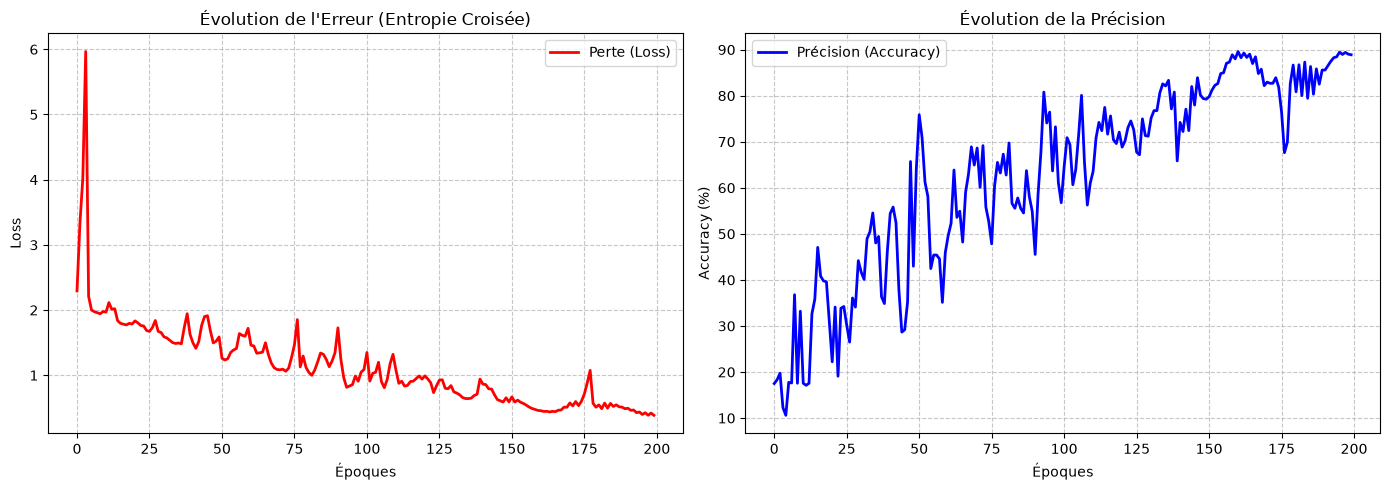

In [14]:
import matplotlib.pyplot as plt

# On ré-instancie le modèle pour repartir de zéro avec des poids frais
nn = ReseauNeurones(input_size=X_ready.shape[1], hidden_size=128, output_size=num_classes, activation_par_defaut='relu')

# Hyperparamètres
epochs = 200           
learning_rate = 0.05   

# Listes pour stocker l'historique et tracer les courbes
historique_loss = []
historique_accuracy = []

print("Début de l'entraînement.\n" + "-"*30)

for epoch in range(epochs):
    # Propagation avant
    y_pred = nn.forward(X_ready)
    
    # Calcul de la loss
    loss = nn.compute_loss(y_one_hot, y_pred)
    historique_loss.append(loss)
    
    # Calcul de l'accuracy
    predictions_classes = np.argmax(y_pred, axis=1)
    vraies_classes = np.argmax(y_one_hot, axis=1)
    accuracy = np.mean(predictions_classes == vraies_classes) * 100
    historique_accuracy.append(accuracy)
    
    # Rétropropagation et mise à jour
    nn.backward(X_ready, y_one_hot)
    nn.update_params(learning_rate)
    
    # Affichage des performances tous les 20 epochs
    if epoch % 20 == 0 or epoch == epochs - 1:
        print(f"Epoch {epoch:3d}/{epochs} - Loss: {loss:.4f} - Accuracy: {accuracy:.2f}%")

print("-" * 30 + "\nEntraînement fini")

# Tracé des courbes d'apprentissage

plt.figure(figsize=(14, 5))

# Courbe de la Loss
plt.subplot(1, 2, 1)
plt.plot(historique_loss, label='Perte (Loss)', color='red', linewidth=2)
plt.title('Évolution de l\'Erreur (Entropie Croisée)')
plt.xlabel('Époques')
plt.ylabel('Loss')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()

# Courbe de l'Accuracy
plt.subplot(1, 2, 2)
plt.plot(historique_accuracy, label='Précision (Accuracy)', color='blue', linewidth=2)
plt.title('Évolution de la Précision')
plt.xlabel('Époques')
plt.ylabel('Accuracy (%)')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()

plt.tight_layout()
plt.show()

### 5.5 : Ajustement du taux d'apprentissage
##### **Observations :** Les courbes de Loss et d'Accuracy du premier entraînement présentaient de fortes oscillations (dents de scie). Cela indique un "overshooting" : le taux d'apprentissage était trop élevé, forçant le modèle à rebondir autour du minimum local.
##### **Action :** Réduction du taux d'apprentissage (`learning_rate`) pour lisser la descente de gradient, et augmentation du nombre d'époques (`epochs`) pour compenser la lenteur de la convergence.

Début de l'entraînement.
------------------------------
Epoch   0/500 - Loss: 2.2672 - Accuracy: 8.43%
Epoch  20/500 - Loss: 1.7829 - Accuracy: 46.42%
Epoch  40/500 - Loss: 1.5775 - Accuracy: 58.11%
Epoch  60/500 - Loss: 1.4203 - Accuracy: 67.11%
Epoch  80/500 - Loss: 1.2906 - Accuracy: 72.09%
Epoch 100/500 - Loss: 1.1823 - Accuracy: 75.93%
Epoch 120/500 - Loss: 1.0902 - Accuracy: 77.33%
Epoch 140/500 - Loss: 1.0085 - Accuracy: 78.29%
Epoch 160/500 - Loss: 0.9389 - Accuracy: 79.44%
Epoch 180/500 - Loss: 0.8793 - Accuracy: 80.97%
Epoch 200/500 - Loss: 0.8272 - Accuracy: 82.25%
Epoch 220/500 - Loss: 0.7813 - Accuracy: 83.01%
Epoch 240/500 - Loss: 0.7407 - Accuracy: 83.91%
Epoch 260/500 - Loss: 0.7045 - Accuracy: 84.36%
Epoch 280/500 - Loss: 0.6718 - Accuracy: 84.67%
Epoch 300/500 - Loss: 0.6422 - Accuracy: 84.93%
Epoch 320/500 - Loss: 0.6152 - Accuracy: 85.25%
Epoch 340/500 - Loss: 0.5904 - Accuracy: 85.63%
Epoch 360/500 - Loss: 0.5675 - Accuracy: 86.14%
Epoch 380/500 - Loss: 0.5464 - Ac

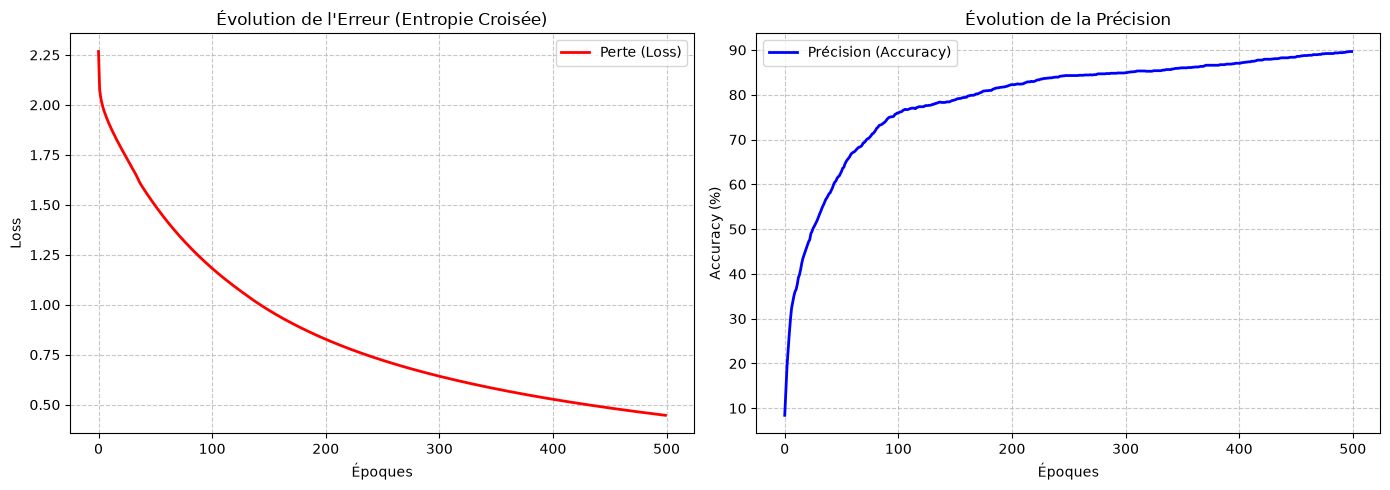

In [15]:
import matplotlib.pyplot as plt

# On ré-instancie le modèle pour repartir de zéro avec des poids frais
nn = ReseauNeurones(input_size=X_ready.shape[1], hidden_size=128, output_size=num_classes, activation_par_defaut='relu')

# Hyperparamètres
epochs = 500           
learning_rate = 0.005  

# Listes pour stocker l'historique et tracer les courbes
historique_loss = []
historique_accuracy = []

print("Début de l'entraînement.\n" + "-"*30)

for epoch in range(epochs):
    # Propagation avant
    y_pred = nn.forward(X_ready)
    
    # Calcul de la loss
    loss = nn.compute_loss(y_one_hot, y_pred)
    historique_loss.append(loss)
    
    # Calcul de l'accuracy
    predictions_classes = np.argmax(y_pred, axis=1)
    vraies_classes = np.argmax(y_one_hot, axis=1)
    accuracy = np.mean(predictions_classes == vraies_classes) * 100
    historique_accuracy.append(accuracy)
    
    # Rétropropagation et mise à jour
    nn.backward(X_ready, y_one_hot)
    nn.update_params(learning_rate)
    
    # Affichage des performances tous les 20 epochs
    if epoch % 20 == 0 or epoch == epochs - 1:
        print(f"Epoch {epoch:3d}/{epochs} - Loss: {loss:.4f} - Accuracy: {accuracy:.2f}%")

print("-" * 30 + "\nEntraînement fini")

# Tracé des courbes d'apprentissage

plt.figure(figsize=(14, 5))

# Courbe de la loss
plt.subplot(1, 2, 1)
plt.plot(historique_loss, label='Perte (Loss)', color='red', linewidth=2)
plt.title('Évolution de l\'Erreur (Entropie Croisée)')
plt.xlabel('Époques')
plt.ylabel('Loss')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()

# Courbe de l'accuracy
plt.subplot(1, 2, 2)
plt.plot(historique_accuracy, label='Précision (Accuracy)', color='blue', linewidth=2)
plt.title('Évolution de la Précision')
plt.xlabel('Époques')
plt.ylabel('Accuracy (%)')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()

plt.tight_layout()
plt.show()

# Partie 6 : Évaluation du modèle

**Méthode :** validation croisée stratifiée à 5 plis sur l'EnsembleB (1 514 images, 8 classes). Chaque image est testée une fois, ce qui est plus fiable qu'un seul découpage, et les proportions des classes sont conservées.

**Hyperparamètres :** dans chaque pli, 12 configurations sont comparées sur 20 % des données d'entraînement (64 ou 128 neurones, taux de 0,005 à 0,02, 400 ou 800 époques). Le plus souvent retenus : 128 neurones, taux de 0,02 et 800 époques (2 plis sur 5), avec ReLU pour limiter la disparition du gradient.

**Résultats :** exactitude moyenne de 95,1 % (± 2,2) et F1 macro moyen de 0,948 (± 0,024).

In [16]:
import time
import pandas as pd
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix

NOMS = ["Cercle2", "Cercle5", "Diamant2", "Diamant5", "Hexagone2", "Hexagone5", "Triangle2", "Triangle5"]

_, indices_uniques = np.unique(X, axis=0, return_index=True)
indices_uniques = np.sort(indices_uniques)

X_eval = X[indices_uniques]
y_sans_doublons = y[indices_uniques]
_, y_eval = np.unique(y_sans_doublons, return_inverse=True)

images_par_classe = np.bincount(y_eval).tolist()
print(X_eval.shape, dict(zip(NOMS, images_par_classe)))

(1514, 4098) {'Cercle2': 189, 'Cercle5': 132, 'Diamant2': 284, 'Diamant5': 159, 'Hexagone2': 270, 'Hexagone5': 150, 'Triangle2': 274, 'Triangle5': 56}


In [17]:
NOMBRE_CARACTERISTIQUES = 2


def separer_pixels_et_caracteristiques(X):
    nombre_pixels = X.shape[1] - NOMBRE_CARACTERISTIQUES
    pixels, caracteristiques = np.hsplit(X, [nombre_pixels])
    return pixels, caracteristiques


def normaliser(X, moyenne, ecart_type):
    pixels, caracteristiques = separer_pixels_et_caracteristiques(X)
    pixels_normalises = pixels / 255.0
    caracteristiques_normalisees = (caracteristiques - moyenne) / ecart_type
    return np.hstack((pixels_normalises, caracteristiques_normalisees))


def preparer(X_entrainement, X_autre):
    _, caracteristiques = separer_pixels_et_caracteristiques(X_entrainement)
    moyenne = np.mean(caracteristiques, axis=0)
    ecart_type = np.std(caracteristiques, axis=0) + 1e-8

    X_entrainement_normalise = normaliser(X_entrainement, moyenne, ecart_type)
    X_autre_normalise = normaliser(X_autre, moyenne, ecart_type)
    return X_entrainement_normalise, X_autre_normalise

In [18]:
def encoder_one_hot(y):
    matrice_identite = np.eye(len(NOMS))
    return matrice_identite[y]


def entrainer_rn(X_train, y_train, hidden_size, learning_rate, epochs, seed=42):
    np.random.seed(seed)
    Y_train = encoder_one_hot(y_train)
    nombre_entrees = X_train.shape[1]
    modele = ReseauNeurones(nombre_entrees, hidden_size, len(NOMS), 'relu')

    for _ in range(epochs):
        modele.forward(X_train)
        modele.backward(X_train, Y_train)
        modele.update_params(learning_rate)

    return modele


def predire(modele, X_data):
    probabilites = modele.forward(X_data)
    return np.argmax(probabilites, axis=1)


def f1_macro(y_vrai, y_pred):
    precision, rappel, f1, support = precision_recall_fscore_support(
        y_vrai, y_pred, average='macro', zero_division=0
    )
    return f1

In [19]:
GRILLE = []
for hidden_size in (64, 128):
    for learning_rate in (0.005, 0.01, 0.02):
        for epochs in (400, 800):
            GRILLE.append((hidden_size, learning_rate, epochs))


def choisir_hyperparametres(X_train_brut, y_train, seed):
    X_sous, X_val, y_sous, y_val = train_test_split(
        X_train_brut, y_train, test_size=0.2, stratify=y_train, random_state=seed
    )
    X_sous, X_val = preparer(X_sous, X_val)

    meilleur_score = -1
    meilleure_config = None

    for config in GRILLE:
        hidden_size, learning_rate, epochs = config
        modele = entrainer_rn(X_sous, y_sous, hidden_size, learning_rate, epochs)
        y_pred_val = predire(modele, X_val)
        score = f1_macro(y_val, y_pred_val)

        if score > meilleur_score:
            meilleur_score = score
            meilleure_config = config

    return meilleure_config

In [20]:
K = 5
skf = StratifiedKFold(n_splits=K, shuffle=True, random_state=42)
plis = list(skf.split(X_eval, y_eval))

resultats = []
predictions_tous_plis = np.zeros_like(y_eval)

for numero, (idx_train, idx_test) in enumerate(plis):
    X_train_brut = X_eval[idx_train]
    y_train = y_eval[idx_train]
    X_test_brut = X_eval[idx_test]
    y_test = y_eval[idx_test]

    config = choisir_hyperparametres(X_train_brut, y_train, seed=42 + numero)
    hidden_size, learning_rate, epochs = config
    X_train, X_test = preparer(X_train_brut, X_test_brut)

    debut = time.perf_counter()
    modele = entrainer_rn(X_train, y_train, hidden_size, learning_rate, epochs)
    temps_train = time.perf_counter() - debut

    debut = time.perf_counter()
    y_pred = predire(modele, X_test)
    temps_pred = time.perf_counter() - debut

    predictions_tous_plis[idx_test] = y_pred

    accuracy = accuracy_score(y_test, y_pred)
    precision, rappel, f1, support = precision_recall_fscore_support(
        y_test, y_pred, average='macro', zero_division=0
    )

    resultats.append({
        "pli": numero,
        "config": config,
        "accuracy": accuracy,
        "precision": precision,
        "rappel": rappel,
        "f1": f1,
        "temps_train_s": temps_train,
        "temps_pred_s": temps_pred,
    })

df_resultats = pd.DataFrame(resultats)
df_resultats

,pli,config,accuracy,precision,rappel,f1,temps_train_s,temps_pred_s
0,0,"(64, 0.02, 800)",0.966997,0.973203,0.970409,0.971570,2.764693,0.000556
1,1,"(128, 0.02, 800)",0.963696,0.947935,0.956736,0.951213,5.696648,0.001164
2,2,"(128, 0.02, 800)",0.953795,0.958756,0.956357,0.956959,6.050037,0.001050
3,3,"(64, 0.02, 800)",0.957096,0.963708,0.940500,0.950048,2.732826,0.000460
4,4,"(128, 0.02, 800)",0.990066,0.992203,0.991460,0.991776,5.702177,0.000942


In [21]:
mesures = df_resultats.drop(columns=["pli", "config"])
print(mesures.agg(["mean", "std"]))

rapport = classification_report(y_eval, predictions_tous_plis, target_names=NOMS, zero_division=0)
print(rapport)

matrice = confusion_matrix(y_eval, predictions_tous_plis)
print(pd.DataFrame(matrice, index=NOMS, columns=NOMS))

      accuracy  precision    rappel        f1  temps_train_s  temps_pred_s
mean  0.966330   0.967161  0.963093  0.964313       4.589276      0.000834
std   0.014258   0.016702  0.019068  0.017579       1.686279      0.000310
              precision    recall  f1-score   support

     Cercle2       0.93      0.95      0.94       189
     Cercle5       0.98      0.98      0.98       132
    Diamant2       0.98      0.99      0.98       284
    Diamant5       0.99      0.95      0.97       159
   Hexagone2       0.95      0.97      0.96       270
   Hexagone5       0.97      0.95      0.96       150
   Triangle2       0.98      0.97      0.97       274
   Triangle5       0.95      0.95      0.95        56

    accuracy                           0.97      1514
   macro avg       0.97      0.96      0.96      1514
weighted avg       0.97      0.97      0.97      1514

           Cercle2  Cercle5  Diamant2  Diamant5  Hexagone2  Hexagone5  \
Cercle2        180        1         1         0    

# Complément : tester une image brute

### Modèle final

Le modèle utilisé pour tester une image est entraîné sur toute l'EnsembleB, avec la configuration la plus souvent retenue par la validation croisée : 128 neurones, taux de 0,02 et 800 époques.

In [22]:
config_finale = (128, 0.02, 800)
hidden_size, learning_rate, epochs = config_finale

pixels, caracteristiques = separer_pixels_et_caracteristiques(X_eval)
moyenne_finale = np.mean(caracteristiques, axis=0)
ecart_type_final = np.std(caracteristiques, axis=0)

X_final = normaliser(X_eval, moyenne_finale, ecart_type_final + 1e-8)
modele_final = entrainer_rn(X_final, y_eval, hidden_size, learning_rate, epochs)

### Prédiction sur une image brute
**Objectif :** Permettre à la fonction de test de traiter une photo brute (non cadrée) en y appliquant automatiquement le même pipeline de prétraitement et de détection par contours que celui utilisé pour créer notre dataset.

Marqueurs détectés avec succès par le pipeline ROI


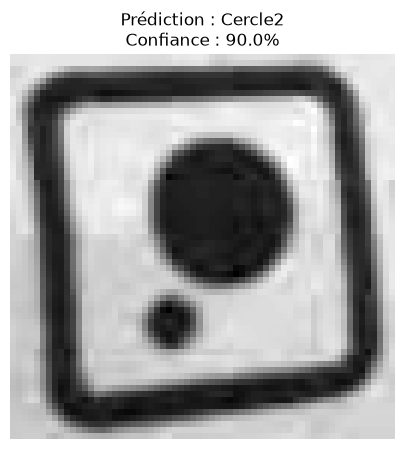

('Cercle2', np.float64(89.98166751682083))

In [23]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Liste des 8 classes 
NOMS_CLASSES = ["Cercle2", "Cercle5", "Diamant2", "Diamant5", "Hexagone2", "Hexagone5", "Triangle2", "Triangle5"]

def predire_image_brute(chemin_image, modele, mean_features, std_features):
    """
    Prend une image brute, extrait automatiquement la ROI via le pipeline OpenCV,
    puis effectue la prédiction avec le réseau de neurones from scratch.
    """
    # Chargement de l'image en grayscale
    image_gray = cv2.imread(chemin_image, cv2.IMREAD_GRAYSCALE)
    if image_gray is None:
        print("Erreur : Impossible de charger l'image. Vérifiez le chemin.")
        return None
        
    h_img, w_img = image_gray.shape

    # Pipeline de détection ROI 
    blurred = cv2.GaussianBlur(image_gray, (3, 3), 0)
    thresh = cv2.adaptiveThreshold(
        blurred, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 31, 3
    )
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
    thresh = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel, iterations=2)

    cnts, hierarchy = cv2.findContours(thresh.copy(), cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)

    candidats_marqueurs = []
    best_box = None

    if hierarchy is not None and len(cnts) > 0:
        hier = hierarchy[0]
        for i, c in enumerate(cnts):
            x, y, w, h = cv2.boundingRect(c)
            box_area = float(w * h)

            # Filtres géométriques stricts
            if x <= 1 or y <= 1 or (x + w) >= (w_img - 1) or (y + h) >= (h_img - 1):
                continue
            if w < 20 or h < 20 or w > (w_img * 0.9) or h > (h_img * 0.9):
                continue

            ar = w / float(h)
            if not (0.82 <= ar <= 1.22):
                continue

            # Vérification de la structure interne
            child_idx = hier[i][2]
            if child_idx == -1:
                continue

            cx, cy, cw, ch = cv2.boundingRect(cnts[child_idx])
            ratio_trou = float(cw * ch) / box_area
            if not (0.35 <= ratio_trou <= 0.82):
                continue

            # Comptage des motifs et contraste
            nb_motifs = 0
            grandchild_idx = hier[child_idx][2]
            while grandchild_idx != -1:
                gc_area = cv2.contourArea(cnts[grandchild_idx])
                if gc_area > 8:
                    nb_motifs += 1
                grandchild_idx = hier[grandchild_idx][0]

            sub_roi = image_gray[y:y+h, x:x+w]
            std_dev = np.std(sub_roi)
            if std_dev < 18:
                continue

            candidats_marqueurs.append({
                'box': (x, y, w, h),
                'nb_motifs': nb_motifs,
                'std': std_dev
            })

    # Tri et sélection du meilleur candidat
    if len(candidats_marqueurs) > 0:
        candidats_marqueurs.sort(key=lambda elem: (elem['nb_motifs'] * 100) + elem['std'], reverse=True)
        best_box = candidats_marqueurs[0]['box']
        nb_motifs_val = candidats_marqueurs[0]['nb_motifs']
    else:
        nb_motifs_val = 0.0

    # Découpage de la ROI, si non trouvé, repli centré
    if best_box is not None:
        x, y, w, h = best_box
        pad = 1
        x1, y1 = max(0, x - pad), max(0, y - pad)
        x2, y2 = min(w_img, x + w + pad), min(h_img, y + h + pad)
        roi = image_gray[y1:y2, x1:x2]
        print("Marqueurs détectés avec succès par le pipeline ROI")
    else:
        margin_w = int(w_img * 0.15)
        margin_h = int(h_img * 0.15)
        roi = image_gray[margin_h:h_img - margin_h, margin_w:w_img - margin_w]
        print("[AVERTISSEMENT] Contour exact non trouvé, application du repli de secours centré.")

    # Redimensionnement 64x64
    roi_resized = cv2.resize(roi, (64, 64))

    # Calcul des caractéristiques pour l'inférence
    std_dev_val = np.std(roi_resized)

    # 5. Aplatissement et normalisation
    pixels_norm = roi_resized.flatten() / 255.0
    features_norm = ([nb_motifs_val, std_dev_val] - mean_features) / (std_features + 1e-8)
    
    # Vecteur d'entrée (1, 4098)
    X_new = np.hstack((pixels_norm, features_norm)).reshape(1, -1)

    # Prédiction du modèle
    probabilites = modele.forward(X_new)
    index_prediction = np.argmax(probabilites, axis=1)[0]
    confiance = probabilites[0][index_prediction] * 100
    nom_prediction = NOMS_CLASSES[index_prediction]

    # Affichage du résultat et de la ROI extraite
    plt.figure(figsize=(5, 5))
    plt.imshow(roi_resized, cmap="gray")
    plt.title(f"Prédiction : {nom_prediction}\nConfiance : {confiance:.1f}%")
    plt.axis("off")
    plt.show()

    return nom_prediction, confiance

chemin_photo = "EnsembleA/Cercles/Cercle2/269_Cercle2.jpg"
predire_image_brute(chemin_photo, modele_final, moyenne_finale, ecart_type_final)

# Partie 7 : Comparaison avec d'autres modèles

In [24]:
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_recall_fscore_support


# Définition des modèles à tester
modeles_sklearn = {
    "SVM": SVC(kernel='rbf', C=10.0, random_state=42),
    "k-NN": KNeighborsClassifier(n_neighbors=5, weights='distance'),
    "RN sklearn": MLPClassifier(
        hidden_layer_sizes=(128,),
        activation='relu',
        solver='sgd',
        learning_rate_init=0.02,
        max_iter=300,
        random_state=42
    )
}

# Validation croisée à 5 plis pour chaque modèle
K = 5
skf = StratifiedKFold(n_splits=K, shuffle=True, random_state=42)

resultats_comparaison = []

for nom_modele, clf in modeles_sklearn.items():
    print(f"\n--> Évaluation de : {nom_modele}.", flush=True)
    
    acc_plis, f1_plis, prec_plis, rap_plis = [], [], [], []
    temps_train_total = 0.0
    temps_pred_total = 0.0
    
    for pli, (idx_tr, idx_te) in enumerate(skf.split(X_eval, y_eval), start=1):
        X_tr, y_tr = X_eval[idx_tr], y_eval[idx_tr]
        X_te, y_te = X_eval[idx_te], y_eval[idx_te]
        
        # Normalisation standardisée sur l'ensemble d'entraînement
        scaler = StandardScaler()
        X_tr_norm = scaler.fit_transform(X_tr)
        X_te_norm = scaler.transform(X_te)
        
        # Entraînement
        t0 = time.perf_counter()
        clf.fit(X_tr_norm, y_tr)
        temps_train_total += (time.perf_counter() - t0)
        
        # Prédiction
        t0 = time.perf_counter()
        y_pred = clf.predict(X_te_norm)
        temps_pred_total += (time.perf_counter() - t0)
        
        # Métriques
        acc = accuracy_score(y_te, y_pred)
        prec, rap, f1, _ = precision_recall_fscore_support(y_te, y_pred, average='macro', zero_division=0)
        
        acc_plis.append(acc)
        f1_plis.append(f1)
        prec_plis.append(prec)
        rap_plis.append(rap)
        
    resultats_comparaison.append({
        "Modèle": nom_modele,
        "Accuracy Moyenne": np.mean(acc_plis),
        "F1-Score": np.mean(f1_plis),
        "Précision": np.mean(prec_plis),
        "Rappel": np.mean(rap_plis),
        "Temps Entraînement Total (s)": temps_train_total,
        "Temps Prédiction Total (s)": temps_pred_total
    })
    print(f"    Terminé : Accuracy = {np.mean(acc_plis):.4f} | F1 = {np.mean(f1_plis):.4f}", flush=True)

df_comp = pd.DataFrame(resultats_comparaison)

# Ajout de de la ligne "From Scratch"
if 'df_resultats' in globals():
    ligne_from_scratch = pd.DataFrame([{
        "Modèle": "RN From Scratch",
        "Accuracy Moyenne": df_resultats["accuracy"].mean(),
        "F1-Score": df_resultats["f1"].mean(),
        "Précision": df_resultats["precision"].mean(),
        "Rappel": df_resultats["rappel"].mean(),
        "Temps Entraînement Total (s)": df_resultats["temps_train_s"].sum(),
        "Temps Prédiction Total (s)": df_resultats["temps_pred_s"].sum()
    }])
    df_comp = pd.concat([ligne_from_scratch, df_comp], ignore_index=True)

print("TABLEAU RÉCAPITULATIF COMPARATIF")
display(df_comp)


--> Évaluation de : SVM.
    Terminé : Accuracy = 0.9650 | F1 = 0.9624

--> Évaluation de : k-NN.
    Terminé : Accuracy = 0.8950 | F1 = 0.8926

--> Évaluation de : RN sklearn.
    Terminé : Accuracy = 0.9564 | F1 = 0.9534
TABLEAU RÉCAPITULATIF COMPARATIF


,Modèle,Accuracy Moyenne,F1-Score,Précision,Rappel,Temps Entraînement Total (s),Temps Prédiction Total (s)
0,RN From Scratch,0.966330,0.964313,0.967161,0.963093,22.946381,0.004171
1,SVM,0.965003,0.962390,0.969018,0.957933,2.436501,1.061966
2,k-NN,0.894990,0.892648,0.921929,0.873999,0.016221,0.088450
3,RN sklearn,0.956418,0.953390,0.955330,0.952442,8.292668,0.008309


# Partie 8 : Tests de scalabilité


--> Évaluation avec 100% des données d'entraînement
    Nombre d'échantillons d'entraînement: 1211

--> Évaluation avec 80% des données d'entraînement
    Nombre d'échantillons d'entraînement: 968

--> Évaluation avec 30% des données d'entraînement
    Nombre d'échantillons d'entraînement: 363


Fraction,100%,30%,80%
Modèle,,,
RN From Scratch,0.970297,0.940594,0.966997
RN sklearn,0.970297,0.940594,0.970297
SVM,0.983498,0.927393,0.973597
k-NN,0.937294,0.838284,0.897690


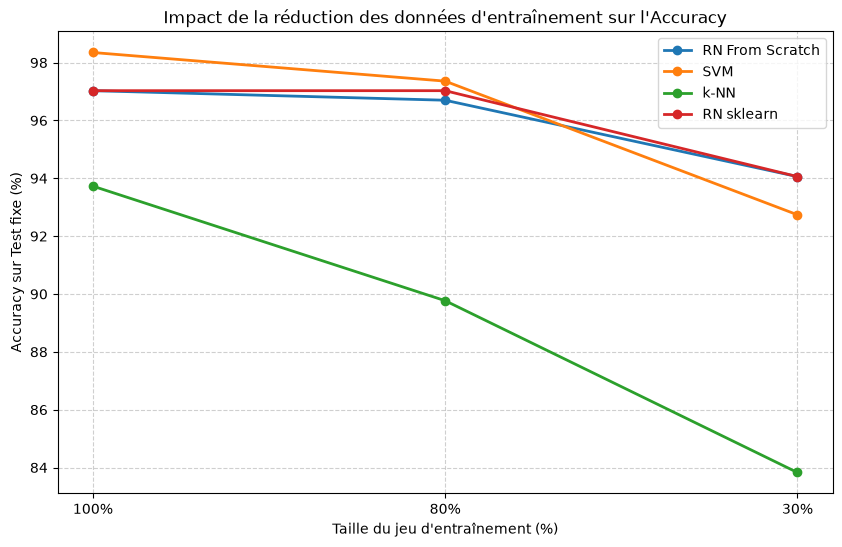

In [25]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score

# Découpage fixe: 80% train initial, 20% test d'évaluation
X_train_complet, X_test_fixe, y_train_complet, y_test_fixe = train_test_split(
    X_eval, y_eval, test_size=0.2, stratify=y_eval, random_state=42
)

fractions = [1.0, 0.8, 0.3]
resultats_scalabilite = []

for frac in fractions:
    pct_label = f"{int(frac * 100)}%"
    print(f"\n--> Évaluation avec {pct_label} des données d'entraînement")
    
    # Sous-échantillonnage de l'entraînement
    if frac < 1.0:
        X_tr_sub, _, y_tr_sub, _ = train_test_split(
            X_train_complet, y_train_complet, train_size=frac, stratify=y_train_complet, random_state=42
        )
    else:
        X_tr_sub, y_tr_sub = X_train_complet, y_train_complet
        
    print(f"    Nombre d'échantillons d'entraînement: {len(y_tr_sub)}")

    # Prétraitement
    # Pour le modèle From Scratch
    X_tr_fs, X_te_fs = preparer(X_tr_sub, X_test_fixe)
    
    # Scikit-learn
    scaler = StandardScaler()
    X_tr_sk = scaler.fit_transform(X_tr_sub)
    X_te_sk = scaler.transform(X_test_fixe)

    # Modèles à évaluer
    modeles = {
        "RN From Scratch": "from_scratch",
        "SVM": SVC(C=10.0, kernel='rbf', random_state=42),
        "k-NN": KNeighborsClassifier(n_neighbors=5, weights='distance'),
        "RN sklearn": MLPClassifier(hidden_layer_sizes=(128,), max_iter=400, random_state=42)
    }

    for nom, clf in modeles.items():
        t0 = time.perf_counter()
        
        if nom == "RN From Scratch":
            # On utilise les hyperparamètres optimaux 
            modele_fs = entrainer_rn(X_tr_fs, y_tr_sub, hidden_size=128, learning_rate=0.02, epochs=800)
            t_train = time.perf_counter() - t0
            y_pred = predire(modele_fs, X_te_fs)
        else:
            clf.fit(X_tr_sk, y_tr_sub)
            t_train = time.perf_counter() - t0
            y_pred = clf.predict(X_te_sk)

        acc = accuracy_score(y_test_fixe, y_pred)
        f1 = f1_score(y_test_fixe, y_pred, average='macro', zero_division=0)

        resultats_scalabilite.append({
            "Fraction": pct_label,
            "Nb Images Train": len(y_tr_sub),
            "Modèle": nom,
            "Accuracy": acc,
            "F1-Score": f1,
            "Temps Train (s)": t_train
        })

df_scalabilite = pd.DataFrame(resultats_scalabilite)
display(df_scalabilite.pivot(index="Modèle", columns="Fraction", values="Accuracy"))

# Visualisation de la scalabilitée
plt.figure(figsize=(10, 6))
for nom in df_scalabilite["Modèle"].unique():
    subset = df_scalabilite[df_scalabilite["Modèle"] == nom]
    plt.plot(subset["Fraction"], subset["Accuracy"] * 100, marker='o', label=nom, linewidth=2)

plt.title("Impact de la réduction des données d'entraînement sur l'Accuracy")
plt.xlabel("Taille du jeu d'entraînement (%)")
plt.ylabel("Accuracy sur Test fixe (%)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.show()